In [5]:
from pathlib import Path
import random
from PIL import Image
import matplotlib.pyplot as plt

images_dir = Path("data/Images")
plots_dir = Path("plots")
plots_dir.mkdir(exist_ok=True)

In [6]:
n_ras = 0
n_zdjec = 0
per_class = {}

for rasa in images_dir.iterdir():
    if not rasa.is_dir():
        continue
    n_ras += 1
    pliki = [p for p in rasa.iterdir() if p.suffix.lower() in (".jpg", ".jpeg")]
    n_zdjec += len(pliki)
    per_class[rasa.name] = len(pliki)

print(n_ras, n_zdjec)
print(min(per_class.values()), max(per_class.values()))

120 20580
148 252


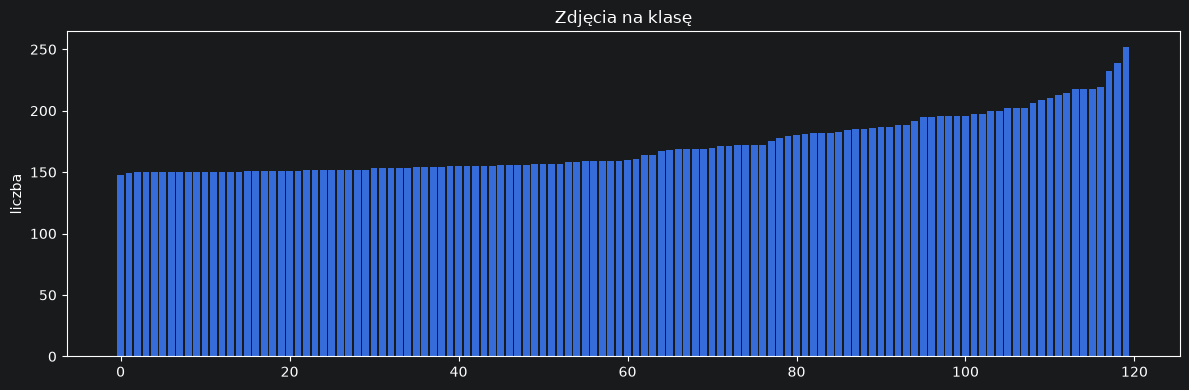

148 252


In [7]:
sorted_counts = sorted(per_class.values())

plt.figure(figsize=(12, 4))
plt.bar(range(len(sorted_counts)), sorted_counts)
plt.title("Zdjęcia na klasę")
plt.ylabel("liczba")
plt.tight_layout()
plt.savefig(plots_dir / "rozklad_klas.png")
plt.show()

print(sorted_counts[0], sorted_counts[-1])

175 2272 444.5833333333333
150 1704 392.30333333333334


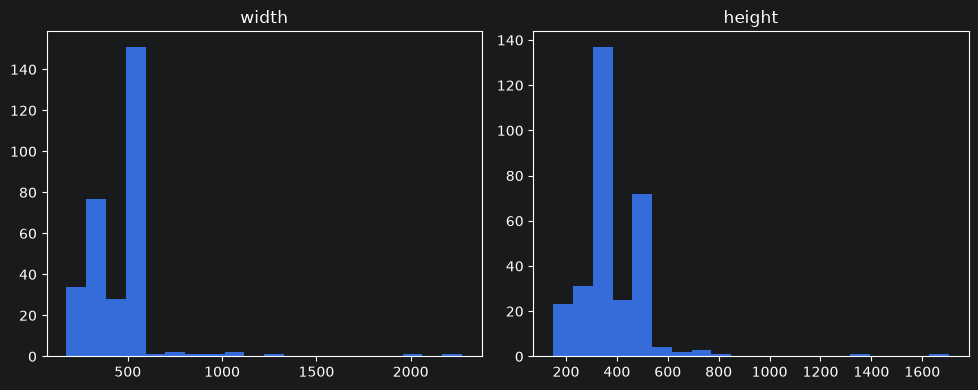

In [8]:
all_files = []
for rasa in images_dir.iterdir():
    if rasa.is_dir():
        for f in rasa.iterdir():
            if f.suffix.lower() in (".jpg", ".jpeg"):
                all_files.append(f)

random.seed(2718)
sample = random.sample(all_files, 300)

widths = []
heights = []
for path in sample:
    img = Image.open(path)
    w, h = img.size
    widths.append(w)
    heights.append(h)
    img.close()

print(min(widths), max(widths), sum(widths) / len(widths))
print(min(heights), max(heights), sum(heights) / len(heights))

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.hist(widths, bins=20)
plt.title("width")
plt.subplot(1, 2, 2)
plt.hist(heights, bins=20)
plt.title("height")
plt.tight_layout()
plt.savefig(plots_dir / "wymiary_obrazow.png")
plt.show()

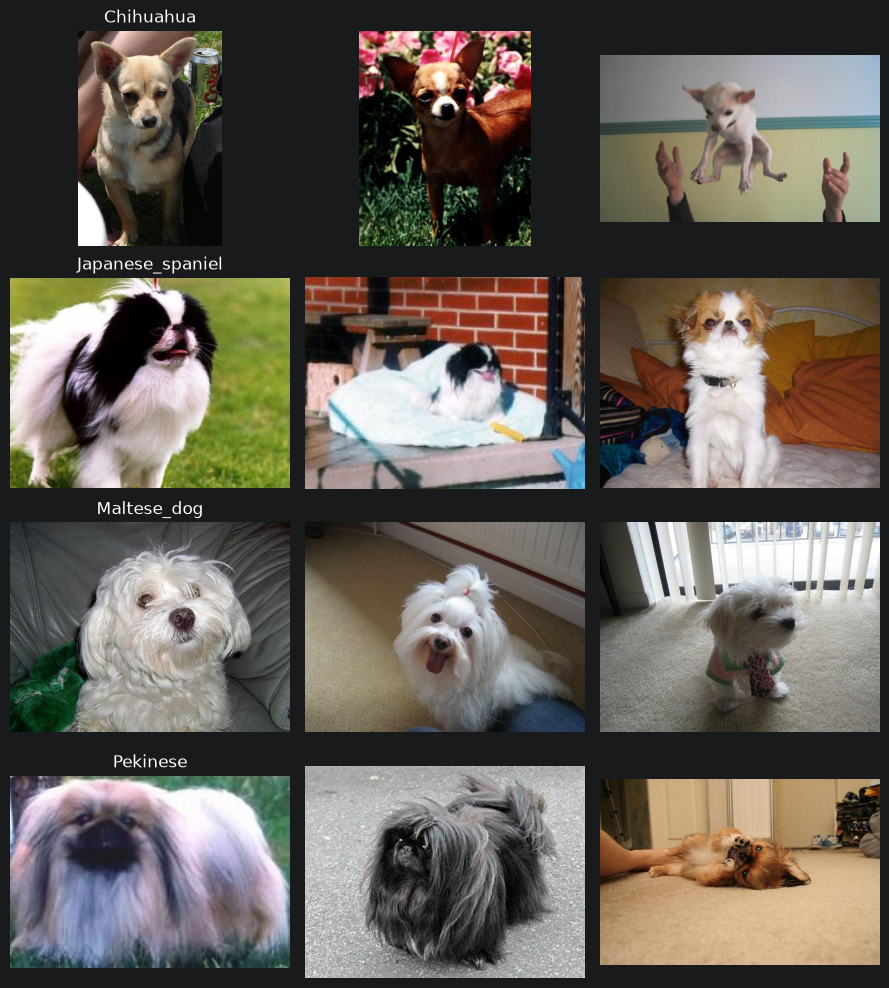

In [9]:
rasy = sorted([p for p in images_dir.iterdir() if p.is_dir()])[:4]

fig, axes = plt.subplots(4, 3, figsize=(9, 10))
for i, rasa in enumerate(rasy):
    pliki = [p for p in rasa.iterdir() if p.suffix.lower() in (".jpg", ".jpeg")]
    nazwa = rasa.name.split("-")[-1]
    for j in range(3):
        axes[i, j].imshow(Image.open(pliki[j]))
        axes[i, j].set_title(nazwa if j == 0 else "")
        axes[i, j].axis("off")

plt.tight_layout()
plt.savefig(plots_dir / "przyklady.png")
plt.show()